# Figure 3 — the 5-qubit QFT

How does the pulse length affect the optimization? How is the condition number of the Jacobian related to GEOPE's succes?

In [1]:
from common import *


In [ ]:
N_RUNS_QFT = 10
L_QFT = [120, 160, 200, 240, 280]
QFT_SPREAD = 1.0 
QFT_MAX_STEPS = 300
QFT_ETA_MAX = 1.0
QFT_LINE_SEARCH = Armijo()


def rydberg_positions(n):
    """2-D atom coordinates, in units of the nearest-neighbour spacing."""
    if n == 5:  # a unit square with an atom in the middle
        return np.array([[0.0, 0.0], [1.0, 0.0], [1.0, 1.0], [0.0, 1.0], [0.5, 0.5]])
    raise NotImplementedError(f"no geometry defined for n = {n}")


def rydberg_couplings(positions):
    """``{(i, j): J_ij}`` over every pair, 1-indexed, with ``J_ij = (r_min/r_ij)**6``.

    Normalised so the strongest coupling is 1.
    """
    n = len(positions)
    pairs = [(i, j) for i in range(1, n + 1) for j in range(i + 1, n + 1)]
    distances = {
        pair: float(np.linalg.norm(positions[pair[0] - 1] - positions[pair[1] - 1]))
        for pair in pairs
    }
    r_min = min(distances.values())
    return {pair: (r_min / r) ** 6 for pair, r in distances.items()}


QFT_COUPLINGS = rydberg_couplings(rydberg_positions(5))


def qft_parameters(n, steps, spread, seed=0):
    """The ``n``-atom Rydberg array of the paper's Fig. 5, targeting the QFT.

    Unlike `make_parameters`, the drift is **distance-weighted**: the couplings
    are the van der Waals ones of the array's actual geometry, not all equal.
    """
    couplings = rydberg_couplings(rydberg_positions(n))
    return Parameters(
        basis=construct_full_pauli_basis(n),
        control={i: ["x", "z"] for i in range(1, n + 1)},
        drift={pair: ["zz"] for pair in couplings},
        drift_values={pair: {"zz": J} for pair, J in couplings.items()},
        target=qft_unitary(n),
        piecewise_steps=steps,
        init_spread=spread,
        seed=seed,
    )


def qft_history():
    """A `History` that also records the least-squares conditioning each step.

    `Geope.ls_diagnostics` is refreshed every step, but `History`'s default
    logging function does not read it -- so the conditioning has to be asked
    for. A custom ``logging_fn`` *replaces* the default row rather than
    extending it, which is why ``fidelities`` is returned here too.
    """
    return History(
        logging_fn=lambda g: {
            "fidelities": g.params.fidelity,
            "ls_cond": g.ls_diagnostics["cond"],
            "ls_rank": g.ls_diagnostics["rank"],
        }
    )


def qft_trajectory(optimiser, init_pulse):
    """One run: ``(fidelity, cond, rank)`` per step, step 0 included.

    Row 0 is the sentinel `Geope.init` records before any solve has happened --
    ``nan`` conditioning and ``rank = -1``. `ls_diagnostics` is written before
    `history.record`, so every later row carries the solve that produced it,
    including a step the Gram-Schmidt fallback replaced.
    """
    optimiser.init(init_parameters=init_pulse)
    optimiser.history.reset()
    optimiser.history.record(optimiser)  # step 0, after the re-init
    optimiser.optimize(
        max_steps=QFT_MAX_STEPS,
        precision=PRECISION,
        line_search=QFT_LINE_SEARCH,
        max_step_size=QFT_ETA_MAX,
    )
    return (
        np.array([float(f) for f in optimiser.history.fidelities]),
        np.array([float(c) for c in optimiser.history.ls_cond]),
        np.array([int(r) for r in optimiser.history.ls_rank]),
    )

In [ ]:
def qft_config(n, steps):
    """Everything that changes this block's numbers.

    The couplings are model data, not presentation, so they belong in the key.
    ``N_RUNS_QFT`` deliberately does not: runs are stored one per entry, so a
    block of 10 *contains* the first 10 of a request for 20.
    """
    return {
        "tag": f"qft_n{n}_L{steps}",
        "kind": "qft-pulse-length",
        "gate": "QFT",
        "n_qubits": n,
        "steps": steps,
        "couplings": {str(k): round(v, 12) for k, v in QFT_COUPLINGS.items()},
        "init_spread": QFT_SPREAD,
        "max_steps": QFT_MAX_STEPS,
        "precision": PRECISION,
        "line_search": repr(QFT_LINE_SEARCH),
        "eta_max": QFT_ETA_MAX,
    }


def qft_paths(cfg):
    """``(npz, json)`` for one pulse length — one folder per L."""
    return cache_paths(cfg, "qft", f"L{cfg['steps']}")


def load_qft_block(npz_path):
    """The runs already stored, or ``None``. Partial by design, as in Figure 1."""
    if not npz_path.exists():
        return None
    with np.load(npz_path) as handle:
        stored = int(handle["totals"].size)
        return (
            [handle[f"fid_{s}"] for s in range(stored)],
            [handle[f"cond_{s}"] for s in range(stored)],
            [handle[f"rank_{s}"] for s in range(stored)],
            list(handle["totals"]),
        )


def save_qft_block(npz_path, json_path, cfg, fids, conds, ranks, totals):
    npz_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        npz_path,
        totals=np.asarray(totals, dtype=float),
        **{f"fid_{s}": v for s, v in enumerate(fids)},
        **{f"cond_{s}": v for s, v in enumerate(conds)},
        **{f"rank_{s}": v for s, v in enumerate(ranks)},
    )
    json_path.write_text(
        json.dumps({**cfg, "n_runs": len(fids)}, indent=1, sort_keys=True)
    )


def qft_sweep(n_runs=None, force=False, verbose=True):
    """Every pulse length, keyed by L. Returns ``{L: (fids, conds, ranks)}``."""
    n_runs = N_RUNS_QFT if n_runs is None else n_runs
    blocks = {}
    for steps in L_QFT:
        cfg = qft_config(5, steps)
        npz_path, json_path = qft_paths(cfg)
        cached = None if force else load_qft_block(npz_path)
        fids, conds, ranks, totals = cached if cached else ([], [], [], [])
        have = len(fids)

        if have >= n_runs:
            note = f"cached ({have} stored)"
        else:
            params = qft_parameters(5, steps, QFT_SPREAD)
            optimiser = Geope(params, history=qft_history())
            started = time.perf_counter()
            for seed in range(have, n_runs):
                pulse = random_pulse(params, np.random.default_rng(seed), QFT_SPREAD)
                run_started = time.perf_counter()
                fid, cond, rank = qft_trajectory(optimiser, pulse)
                fids.append(fid)
                conds.append(cond)
                ranks.append(rank)
                totals.append(time.perf_counter() - run_started)
                save_qft_block(npz_path, json_path, cfg, fids, conds, ranks, totals)
            note = (
                f"computed {n_runs - have} of {n_runs} in "
                f"{time.perf_counter() - started:.0f}s"
            )

        full_rank = 4**5 - 1
        for rank in ranks[:n_runs]:
            assert np.all(rank[1:] == full_rank), (
                f"L={steps}: rank dropped below {full_rank}; cond is being read "
                f"over a truncated spectrum"
            )

        blocks[steps] = (fids[:n_runs], conds[:n_runs], ranks[:n_runs])
        if verbose:
            reached = sum(f[-1] > PRECISION for f in fids[:n_runs])
            print(
                f"  {cfg['tag']:22s} {reached:2d}/{n_runs} converged  "
                f"median {float(np.median([f.size - 1 for f in fids[:n_runs]])):5.1f} steps  "
                f"cond {float(np.median(conds[0][1:])):7.2f}   {note}",
                flush=True,
            )
    return blocks


qft_blocks = qft_sweep()

  qft_n5_L120            10/10 converged  median  93.5 steps  cond   56.74   cached (10 stored)
  qft_n5_L160            10/10 converged  median  59.5 steps  cond   18.98   cached (10 stored)
  qft_n5_L200            10/10 converged  median  49.0 steps  cond   11.81   cached (10 stored)
  qft_n5_L240            10/10 converged  median  44.5 steps  cond    8.85   cached (10 stored)
  qft_n5_L280            10/10 converged  median  41.5 steps  cond    7.19   cached (10 stored)


/var/folders/m4/hkhn64pj5x9_xxq4wkncth480000gp/T/ipykernel_38572/1567585162.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=0.3)


figures/fig3_qft5_pulse_length.pdf


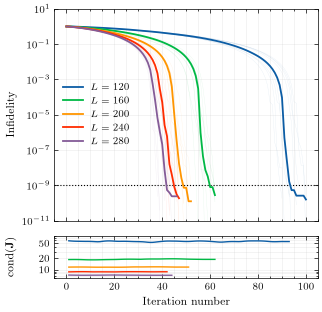

In [ ]:
QFT_COLOURS = dict(zip(L_QFT, SCIENCEPLOT_COLOURS))
fig, (ax, ax_cond) = plt.subplots(
    2, 1, figsize=(ONE_COLUMN, 3.5), sharex=True,
    gridspec_kw=dict(height_ratios=[5, 1.0], hspace=0.12),
)

for steps in L_QFT:
    fids, _conds, _ranks = qft_blocks[steps]
    for f in fids:
        y = np.clip(1.0 - f, 1e-18, None)
        ax.semilogy(np.arange(y.size), y, color=QFT_COLOURS[steps], **FAINT)
for steps in L_QFT:
    fids, _conds, _ranks = qft_blocks[steps]
    y = median_over_runs([np.clip(1.0 - f, 1e-18, None) for f in fids])
    ax.semilogy(
        np.arange(y.size), y, color=QFT_COLOURS[steps], lw=1.3, zorder=3,
        label=rf"$L = {steps}$",
    )

ax.axhline(1.0 - PRECISION, color="black", ls=":", lw=0.8, zorder=2)
ax.set_ylabel(r"Infidelity")
ax.set_ylim(1e-11, 10.0)
ax.grid(alpha=0.25, which="both", lw=0.4)

ax.legend(loc="center left")

for steps in L_QFT:
    _fids, conds, _ranks = qft_blocks[steps]
    c = conds[0]
    ax_cond.plot(np.arange(1, c.size), c[1:], color=QFT_COLOURS[steps], lw=1.0)
ax_cond.set_yscale("log")
ax_cond.set_ylim(6, 80)
ax_cond.set_yticks([10, 20, 50])
ax_cond.set_yticklabels(["10", "20", "50"])
ax_cond.yaxis.set_minor_formatter(NullFormatter())
ax_cond.set_xlabel("Iteration number")
ax_cond.set_ylabel(r"cond$(\mathbf{J})$")
ax_cond.grid(alpha=0.25, which="both", lw=0.4)

fig.align_ylabels((ax, ax_cond))
fig.tight_layout(pad=0.3)
print(save_figure(fig, "fig3_qft5_pulse_length"))
plt.show()